In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import shap

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

from imblearn.over_sampling import SMOTE

In [8]:
df = pd.read_csv("healthcare_dataset.csv")
print(df.head())
print(df.shape)

            Name  Age  Gender Blood Type Medical Condition Date of Admission  \
0  Bobby JacksOn   30    Male         B-            Cancer        2024-01-31   
1   LesLie TErRy   62    Male         A+           Obesity        2019-08-20   
2    DaNnY sMitH   76  Female         A-           Obesity        2022-09-22   
3   andrEw waTtS   28  Female         O+          Diabetes        2020-11-18   
4  adrIENNE bEll   43  Female        AB+            Cancer        2022-09-19   

             Doctor                    Hospital Insurance Provider  \
0     Matthew Smith             Sons and Miller         Blue Cross   
1   Samantha Davies                     Kim Inc           Medicare   
2  Tiffany Mitchell                    Cook PLC              Aetna   
3       Kevin Wells  Hernandez Rogers and Vang,           Medicare   
4    Kathleen Hanna                 White-White              Aetna   

   Billing Amount  Room Number Admission Type Discharge Date   Medication  \
0    18856.281306    

In [9]:
#Feature Engineering
df['Date of Admission'] = pd.to_datetime(df['Date of Admission'])
df['Discharge Date'] = pd.to_datetime(df['Discharge Date'])
df['Length_of_Stay'] = (
    df['Discharge Date'] - df['Date of Admission']
).dt.days
df['Billing_per_Day'] = (
    df['Billing Amount'] /
    (df['Length_of_Stay'] + 1)
)
print(df[['Length_of_Stay','Billing_per_Day']].head())

   Length_of_Stay  Billing_per_Day
0               2      6285.427102
1               6      4806.189612
2              15      1747.193505
3              30      1222.896207
4              20       678.015134


In [10]:
# Binary Classification
df['Test Results'] = df['Test Results'].replace({
    'Normal': 0,
    'Abnormal': 1,
    'Inconclusive': 1
})
print(df['Test Results'].value_counts())

Test Results
1    36983
0    18517
Name: count, dtype: int64


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13748\303570984.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Test Results'] = df['Test Results'].replace({


In [11]:
numeric_cols = [
    'Age',
    'Billing Amount',
    'Length_of_Stay',
    'Billing_per_Day'
]
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = np.where(df[col] > upper, upper, df[col])
    df[col] = np.where(df[col] < lower, lower, df[col])



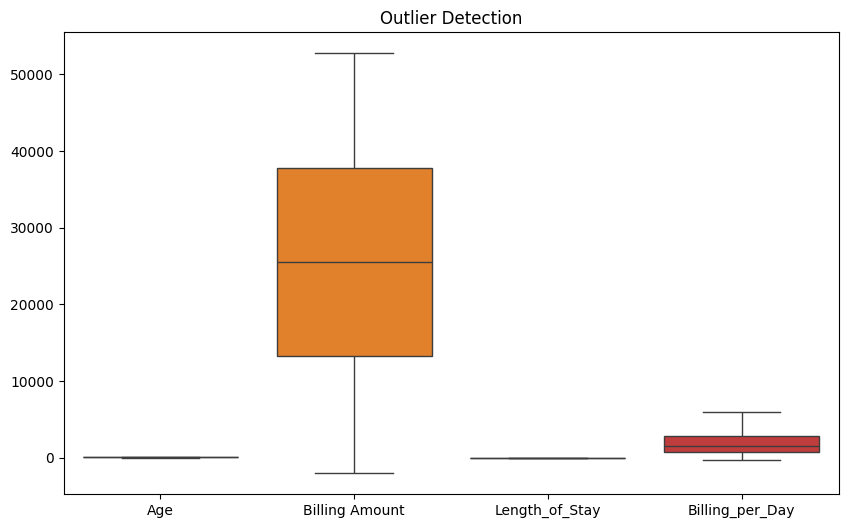

In [12]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[numeric_cols])
plt.title("Outlier Detection")
plt.show()

In [13]:
#EDA
print(df.info())
print(df.describe())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Name                55500 non-null  object        
 1   Age                 55500 non-null  float64       
 2   Gender              55500 non-null  object        
 3   Blood Type          55500 non-null  object        
 4   Medical Condition   55500 non-null  object        
 5   Date of Admission   55500 non-null  datetime64[ns]
 6   Doctor              55500 non-null  object        
 7   Hospital            55500 non-null  object        
 8   Insurance Provider  55500 non-null  object        
 9   Billing Amount      55500 non-null  float64       
 10  Room Number         55500 non-null  int64         
 11  Admission Type      55500 non-null  object        
 12  Discharge Date      55500 non-null  datetime64[ns]
 13  Medication          55500 non-null  object    

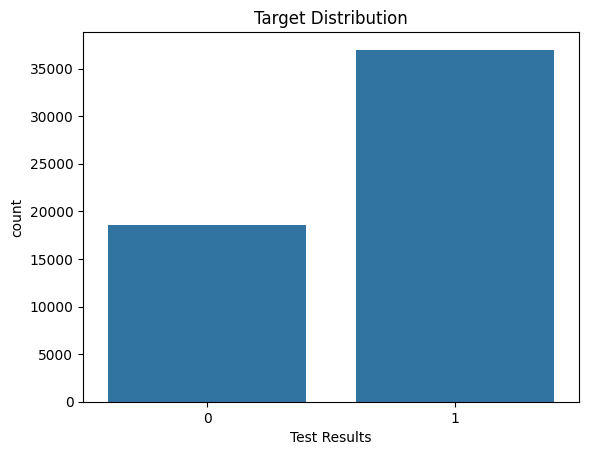

In [14]:
sns.countplot(x='Test Results', data=df)
plt.title("Target Distribution")
plt.show()

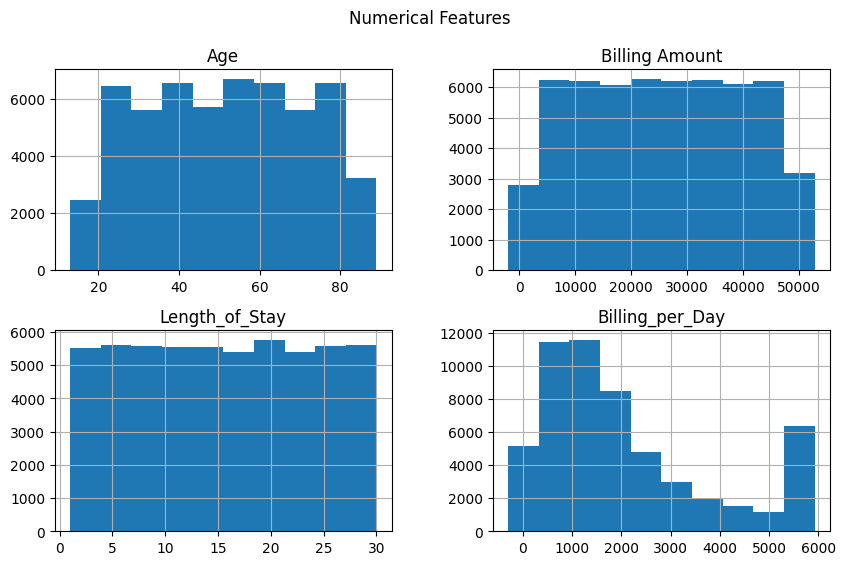

In [15]:
df[['Age',
    'Billing Amount',
    'Length_of_Stay',
    'Billing_per_Day']].hist(figsize=(10,6))

plt.suptitle("Numerical Features")
plt.show()

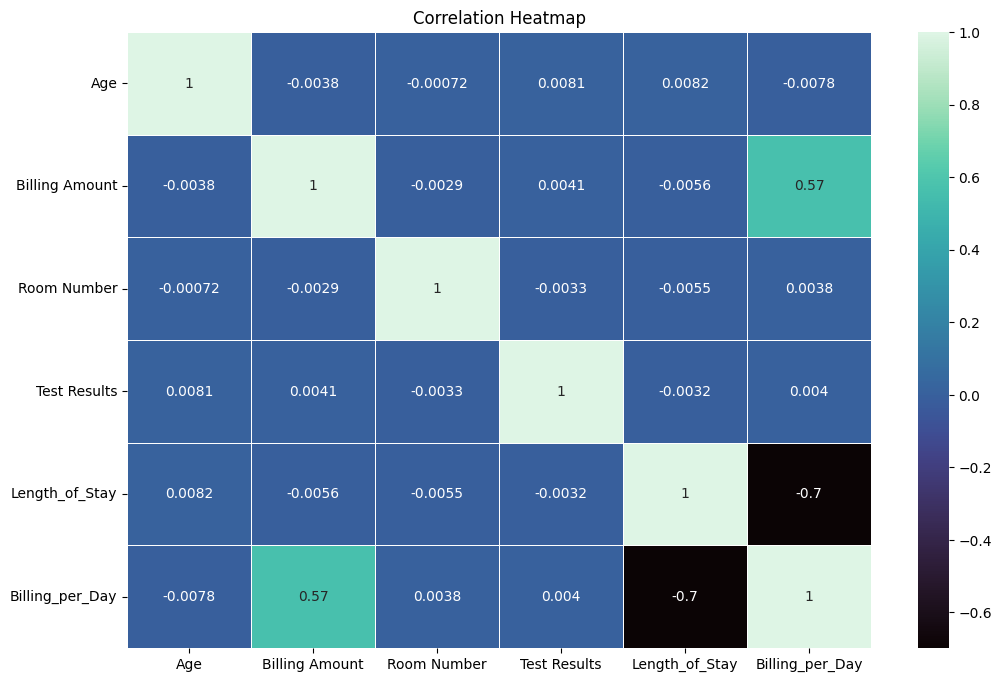

In [16]:
plt.figure(figsize=(12,8))
corr = df.corr(numeric_only=True)
sns.heatmap(
    corr,
    annot=True,
    cmap='mako',
    linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.show()

In [17]:
columns_to_drop = [
    'Name',
    'Doctor',
    'Hospital',
    'Date of Admission',
    'Discharge Date'
]
df = df.drop(columns=columns_to_drop, errors='ignore')
print(df.columns)

Index(['Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Insurance Provider', 'Billing Amount', 'Room Number', 'Admission Type',
       'Medication', 'Test Results', 'Length_of_Stay', 'Billing_per_Day'],
      dtype='object')


In [18]:
num_cols = df.select_dtypes(include=['int64','float64']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
print(df.isnull().sum())

Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Medication            0
Test Results          0
Length_of_Stay        0
Billing_per_Day       0
dtype: int64


In [19]:
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])
print(df.dtypes)

Age                   float64
Gender                  int64
Blood Type              int64
Medical Condition       int64
Insurance Provider      int64
Billing Amount        float64
Room Number             int64
Admission Type          int64
Medication              int64
Test Results            int64
Length_of_Stay        float64
Billing_per_Day       float64
dtype: object


In [20]:
X = df.drop('Test Results', axis=1)
y = df['Test Results']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print(X_train.shape)
print(X_test.shape)

(44400, 11)
(11100, 11)


In [21]:
X_train = X_train.select_dtypes(include=['int64','float64'])
X_test = X_test.select_dtypes(include=['int64','float64'])
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [22]:

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=10,
            class_weight='balanced'
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            class_weight='balanced',
            n_jobs=-1
        ),

    "Naive Bayes":
        GaussianNB(),

    "Gradient Boosting":
        GradientBoostingClassifier(),

    "KNN":
        KNeighborsClassifier(
            n_neighbors=7
        ),

    "SVM":
        SVC(
            kernel='linear',  
            probability=False,
            class_weight='balanced'
        )
}
results_before = []
for name, model in models.items():
    print(f"\nTraining {name}...")
    start = time.time()
    if name in ['KNN', 'SVM']:
        X_small = X_train[:10000]
        y_small = y_train[:10000]
        model.fit(X_small, y_small)
    else:
        model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    end = time.time()
    results_before.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        round(end-start, 2)
    ])
before_df = pd.DataFrame(
    results_before,
    columns=[
        'Model',
        'Accuracy_before',
        'Precision_before',
        'Recall_before',
        'F1_before',
        'Time'
    ]
)
print(before_df)


Training Logistic Regression...



Training Decision Tree...

Training Random Forest...

Training Naive Bayes...

Training Gradient Boosting...

Training KNN...

Training SVM...
                 Model  Accuracy_before  Precision_before  Recall_before  \
0  Logistic Regression         0.501532          0.665110       0.502239   
1        Decision Tree         0.512523          0.668385       0.527744   
2        Random Forest         0.605225          0.685999       0.747795   
3          Naive Bayes         0.664054          0.664054       1.000000   
4    Gradient Boosting         0.663694          0.664081       0.998779   
5                  KNN         0.611441          0.666594       0.830009   
6                  SVM         0.485495          0.657257       0.470628   

   F1_before   Time  
0   0.572312   0.11  
1   0.589796   0.68  
2   0.715565   3.50  
3   0.798116   0.04  
4   0.797746  14.43  
5   0.739380   2.38  
6   0.548502   8.00  


In [23]:
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(
    X_train,
    y_train
)
print(y_train.value_counts())
print(pd.Series(y_train_sm).value_counts())

Test Results
1    29612
0    14788
Name: count, dtype: int64
Test Results
1    29612
0    29612
Name: count, dtype: int64


In [24]:
results_after = []
for name, model in models.items():

    model.fit(X_train_sm, y_train_sm)

    y_pred = model.predict(X_test)

    results_after.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ])

results_df = pd.DataFrame(
    results_after,
    columns=[
        'Model',
        'Accuracy_after',
        'Precision_after',
        'Recall_after',
        'F1_after'
    ]
)

print(results_df)

                 Model  Accuracy_after  Precision_after  Recall_after  \
0  Logistic Regression        0.493333         0.659718      0.489486   
1        Decision Tree        0.650000         0.665559      0.950617   
2        Random Forest        0.661982         0.665266      0.988197   
3          Naive Bayes        0.498739         0.669226      0.484737   
4    Gradient Boosting        0.664054         0.664054      1.000000   
5                  KNN        0.546486         0.700051      0.554742   
6                  SVM        0.500000         0.666789      0.493827   

   F1_after  
0  0.561994  
1  0.782949  
2  0.795197  
3  0.562234  
4  0.798116  
5  0.618983  
6  0.567420  


                 Model  Accuracy_before  Precision_before  Recall_before  \
0  Logistic Regression         0.501532          0.665110       0.502239   
1        Decision Tree         0.512523          0.668385       0.527744   
2        Random Forest         0.605225          0.685999       0.747795   
3          Naive Bayes         0.664054          0.664054       1.000000   
4    Gradient Boosting         0.663694          0.664081       0.998779   
5                  KNN         0.611441          0.666594       0.830009   
6                  SVM         0.485495          0.657257       0.470628   

   F1_before   Time  Accuracy_after  Precision_after  Recall_after  F1_after  
0   0.572312   0.11        0.493333         0.659718      0.489486  0.561994  
1   0.589796   0.68        0.650000         0.665559      0.950617  0.782949  
2   0.715565   3.50        0.661982         0.665266      0.988197  0.795197  
3   0.798116   0.04        0.498739         0.669226      0.484737  0.56223

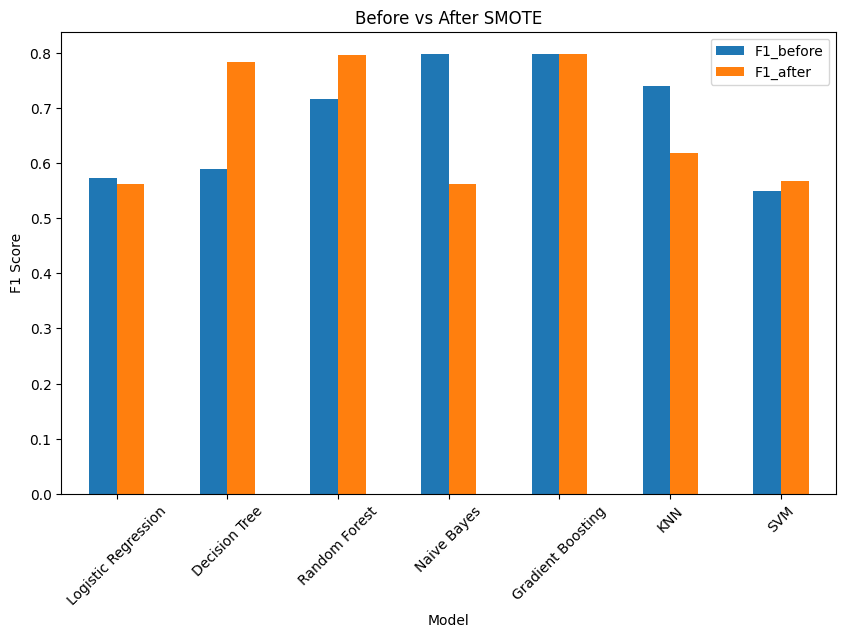

In [25]:
comparison = pd.merge(
    before_df,
    results_df,
    on='Model'
)

print(comparison)

comparison.plot(
    x='Model',
    y=['F1_before','F1_after'],
    kind='bar',
    figsize=(10,6)
)

plt.title("Before vs After SMOTE")
plt.ylabel("F1 Score")

plt.xticks(rotation=45)

plt.show()

In [26]:
best_model_name = results_df.sort_values(
    by='F1_after',
    ascending=False
).iloc[0]['Model']
print("Best Model:", best_model_name)
best_model = models[best_model_name]

Best Model: Gradient Boosting


In [27]:
# Fine Tuning
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10]
}

grid = GridSearchCV(
    RandomForestClassifier(class_weight='balanced'),
    param_grid,
    cv=3,
    scoring='f1'
)

grid.fit(X_train_sm, y_train_sm)

best_model = grid.best_estimator_

print(grid.best_params_)

{'max_depth': 10, 'n_estimators': 200}


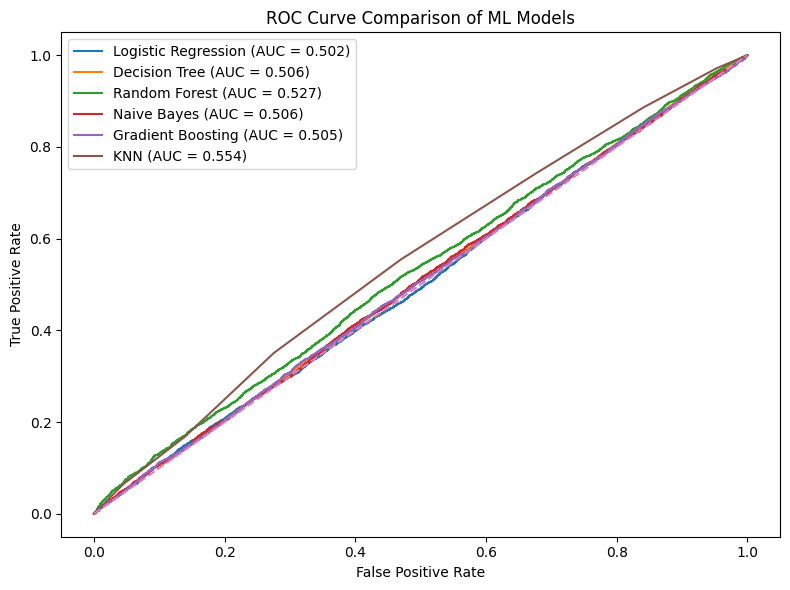

In [28]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
roc_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Decision Tree": models["Decision Tree"],
    "Random Forest": best_model,
    "Naive Bayes": models["Naive Bayes"],
    "Gradient Boosting": models["Gradient Boosting"],
    "KNN": models["KNN"]
}
for name, model in roc_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of ML Models")
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
y_pred = best_model.predict(X_test)
print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

print("F1 Score:",
      f1_score(y_test, y_pred))

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred))

Accuracy: 0.6635135135135135
Precision: 0.6647335991301196
Recall: 0.9952516619183286
F1 Score: 0.7970880643233552

Classification Report:

              precision    recall  f1-score   support

           0       0.45      0.01      0.02      3729
           1       0.66      1.00      0.80      7371

    accuracy                           0.66     11100
   macro avg       0.56      0.50      0.41     11100
weighted avg       0.59      0.66      0.53     11100



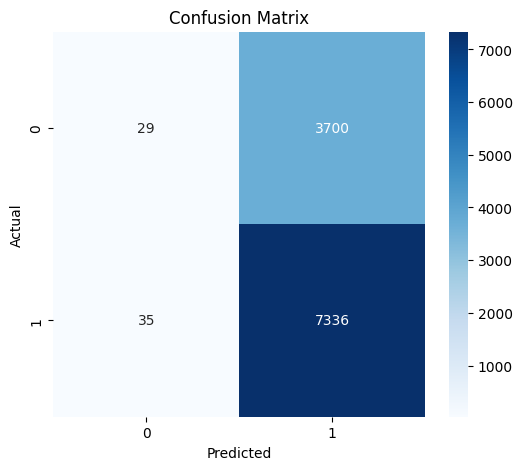

In [30]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [31]:
X_test_df = pd.DataFrame(
    X_test,
    columns=X.columns
)
X_test_df['Actual'] = y_test.values
X_test_df['Predicted'] = y_pred
for gender in X_test_df['Gender'].unique():
    group = X_test_df[
        X_test_df['Gender'] == gender
    ]
    print(f"\nGender: {gender}")
    print(
        "Accuracy:",
        accuracy_score(
            group['Actual'],
            group['Predicted']
        )
    )
    print(
        "F1 Score:",
        f1_score(
            group['Actual'],
            group['Predicted']
        )
    )


Gender: 0.9979750232342119
Accuracy: 0.6588894917706638
F1 Score: 0.7935187212612218

Gender: -1.0020290856170184
Accuracy: 0.6681026745647101
F1 Score: 0.8006039038067507


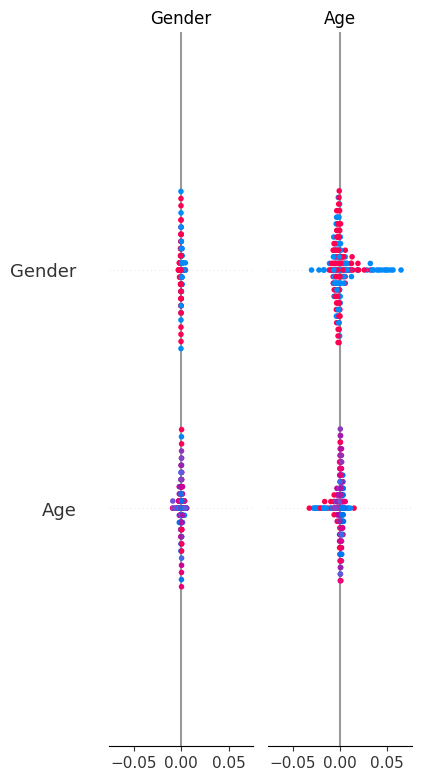

In [32]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
X_sample = pd.DataFrame(
    X_test,
    columns=X.columns
).sample(200, random_state=42)
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_sample)
shap.summary_plot(
    shap_values,
    X_sample,
    show=False
)
plt.xlabel("")
fig = plt.gcf()
fig.set_size_inches(12, 8)
plt.show()


               Feature  Importance
3    Medical Condition    0.206982
2           Blood Type    0.191333
8           Medication    0.158449
4   Insurance Provider    0.152624
9       Length_of_Stay    0.075178
6          Room Number    0.051578
5       Billing Amount    0.051115
0                  Age    0.049579
10     Billing_per_Day    0.041948
7       Admission Type    0.014981
1               Gender    0.006232


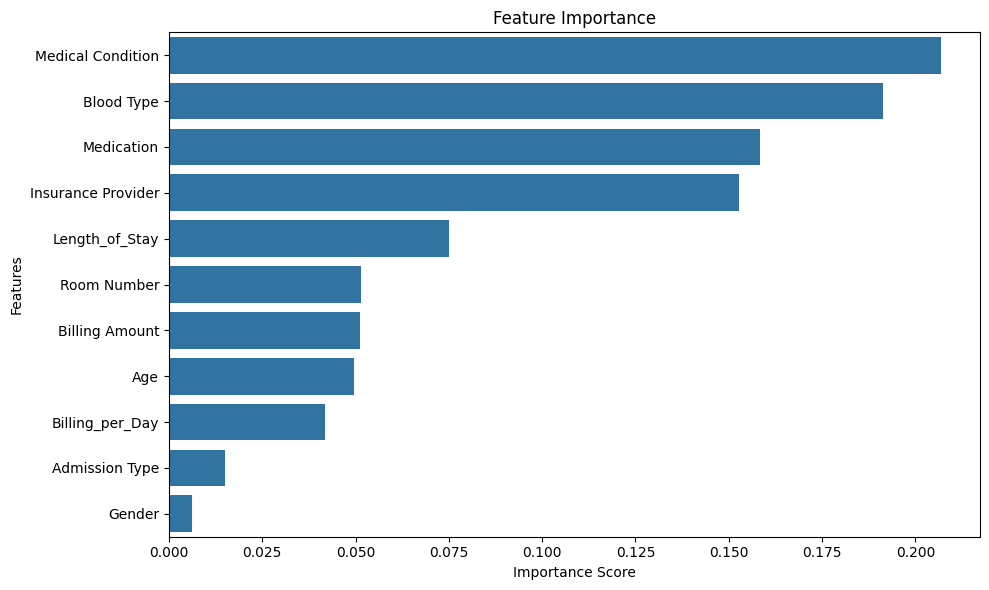

In [34]:
# Get feature importances
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_
})

# Sort values
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Print top features
print(feature_importance)

# Plot
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.tight_layout()

plt.show()